<a href="https://colab.research.google.com/github/Meltdown02/Probabilidad-/blob/main/Unidad6/PracticaFinalU6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**PROBABILIDAD Y ESTADISTICA**
##**PRACTICA FINAL: ANALISIS ESTADISTICO COVID**
##UNIDAD 6
##GRUPO 2Y
##PERIODO AGOSTO-DICIEMBRE 2026
##27 DE NOVIEMBRE DEL 2026
##ALUMNO: MARCO ANTONIO AGUILAR RUIZ
##FACILITADOR: JOSE GABRIEL RODRIGUEZ RIVAS



In [2]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


drive.mount('/content/drive')

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

ruta_archivo = '/content/drive/MyDrive/covid2020-2021-codificado.csv'
df = pd.read_csv(ruta_archivo, low_memory=False)

print(f"Registros cargados: {len(df):,} | Columnas: {df.shape[1]}")
print("Columnas disponibles:", list(df.columns))
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Registros cargados: 12,634,194 | Columnas: 21
Columnas disponibles: ['SECTOR', 'SEXO', 'ENTIDAD_NAC', 'TIPO_PACIENTE', 'FECHA_INGRESO', 'FECHA_DEF', 'INTUBADO', 'NEUMONIA', 'EDAD', 'EMBARAZO', 'INDIGENA', 'DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO', 'RESULTADO_ANTIGENO', 'UCI']


,SECTOR,SEXO,ENTIDAD_NAC,TIPO_PACIENTE,FECHA_INGRESO,FECHA_DEF,INTUBADO,NEUMONIA,EDAD,EMBARAZO,...,DIABETES,EPOC,ASMA,HIPERTENSION,CARDIOVASCULAR,OBESIDAD,RENAL_CRONICA,TABAQUISMO,RESULTADO_ANTIGENO,UCI
0,Issste,Femenino,San Luis Potosí,Ambulatorio,2020-12-06,9999-99-99,No aplica,No,55,No,...,Si,No,No,No,No,No,No,No,Pendiente,No aplica
1,Issste,Masculino,San Luis Potosí,Ambulatorio,2020-02-20,9999-99-99,No aplica,No,59,No aplica,...,No,No,No,No,No,No,No,No,Pendiente,No aplica
2,Ssa,Femenino,Jalisco,Ambulatorio,2020-04-22,9999-99-99,No aplica,No,42,No,...,No,No,Si,No,No,No,No,No,Pendiente,No aplica
3,Ssa,Masculino,Chihuahua,Ambulatorio,2020-07-28,9999-99-99,No aplica,No,35,No aplica,...,No,No,No,No,No,No,No,No,Pendiente,No aplica
4,Ssa,Masculino,Ciudad De México,Ambulatorio,2020-08-18,9999-99-99,No aplica,No,51,No aplica,...,No,No,No,Si,No,No,No,No,Pendiente,No aplica


In [3]:
total_registros = len(df)
print(f"Total general de registros en la base: {total_registros:,}\n")

# Detectar columna de resultado
col_resultado = (
    'RESULTADO_ANTIGENO' if 'RESULTADO_ANTIGENO' in df.columns
    else ('RESULTADO_LAB' if 'RESULTADO_LAB' in df.columns else None)
)

# 1. Positivos, negativos y pendientes
if col_resultado:
    res_norm = df[col_resultado].fillna('No especificado').astype(str).str.strip().str.lower()
    positivos = res_norm.str.contains('positiv', na=False).sum()
    negativos = res_norm.str.contains('negativ', na=False).sum()
    pendientes = res_norm.str.contains('pendient', na=False).sum()
    print(f"--- Resultados ({col_resultado}) ---")
    print(df[col_resultado].value_counts(dropna=False))
    print(f"Positivos: {positivos:,} | Negativos: {negativos:,} | Pendientes: {pendientes:,}\n")

# 2. Pacientes hospitalizados y ambulatorios
if 'TIPO_PACIENTE' in df.columns:
    tipo_norm = df['TIPO_PACIENTE'].fillna('No especificado').astype(str).str.strip().str.lower()
    hosp = tipo_norm.isin(['hospitalizado', '2']).sum()
    amb = tipo_norm.isin(['ambulatorio', '1']).sum()
    print("--- Tipo de paciente ---")
    print(df['TIPO_PACIENTE'].value_counts(dropna=False))
    print(f"Hospitalizados: {hosp:,} | Ambulatorios: {amb:,}\n")

# 3. Pacientes embarazadas
if 'EMBARAZO' in df.columns:
    emb_norm = df['EMBARAZO'].fillna('').astype(str).str.strip().str.lower()
    embarazadas = emb_norm.isin(['si', 'sí', 'si, en gestacion', 'sí, en gestación']).sum()
    print("--- Embarazo ---")
    print(df['EMBARAZO'].value_counts(dropna=False))
    print(f"Pacientes embarazadas: {embarazadas:,}\n")

# 4. Población indígena
if 'INDIGENA' in df.columns:
    ind_norm = df['INDIGENA'].fillna('').astype(str).str.strip().str.lower()
    indigenas = ind_norm.isin(['si', 'sí']).sum()
    nulos_ind = df['INDIGENA'].isna().sum()
    print("--- Población indígena ---")
    print(df['INDIGENA'].value_counts(dropna=False))
    print(
        f"Pacientes indígenas: {indigenas:,} "
        f"(sobre {df['INDIGENA'].notna().sum():,} registros con dato no nulo; "
        f"{nulos_ind:,} valores faltantes/NaN)\n"
    )

# Estadísticos descriptivos de edad
if 'EDAD' in df.columns:
    edad_valida = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 120)]
    print("--- Estadísticos de EDAD (0 a 120 años) ---")
    print(edad_valida.describe().round(2))

Total general de registros en la base: 12,634,194

--- Resultados (RESULTADO_ANTIGENO) ---
RESULTADO_ANTIGENO
Negativo     5853547
Pendiente    5005939
Positivo     1774708
Name: count, dtype: int64
Positivos: 1,774,708 | Negativos: 5,853,547 | Pendientes: 5,005,939

--- Tipo de paciente ---
TIPO_PACIENTE
Ambulatorio      11543303
Hospitalizado     1090891
Name: count, dtype: int64
Hospitalizados: 1,090,891 | Ambulatorios: 11,543,303

--- Embarazo ---
EMBARAZO
No                 6483614
No aplica          5985456
Si                  122583
Se ignora            42529
No especificado         12
Name: count, dtype: int64
Pacientes embarazadas: 122,583

--- Población indígena ---
INDIGENA
NaN                8765798
No                 3665974
No especificado     167182
Si                   35240
Name: count, dtype: int64
Pacientes indígenas: 35,240 (sobre 3,868,396 registros con dato no nulo; 8,765,798 valores faltantes/NaN)

--- Estadísticos de EDAD (0 a 120 años) ---
count    12630604.00


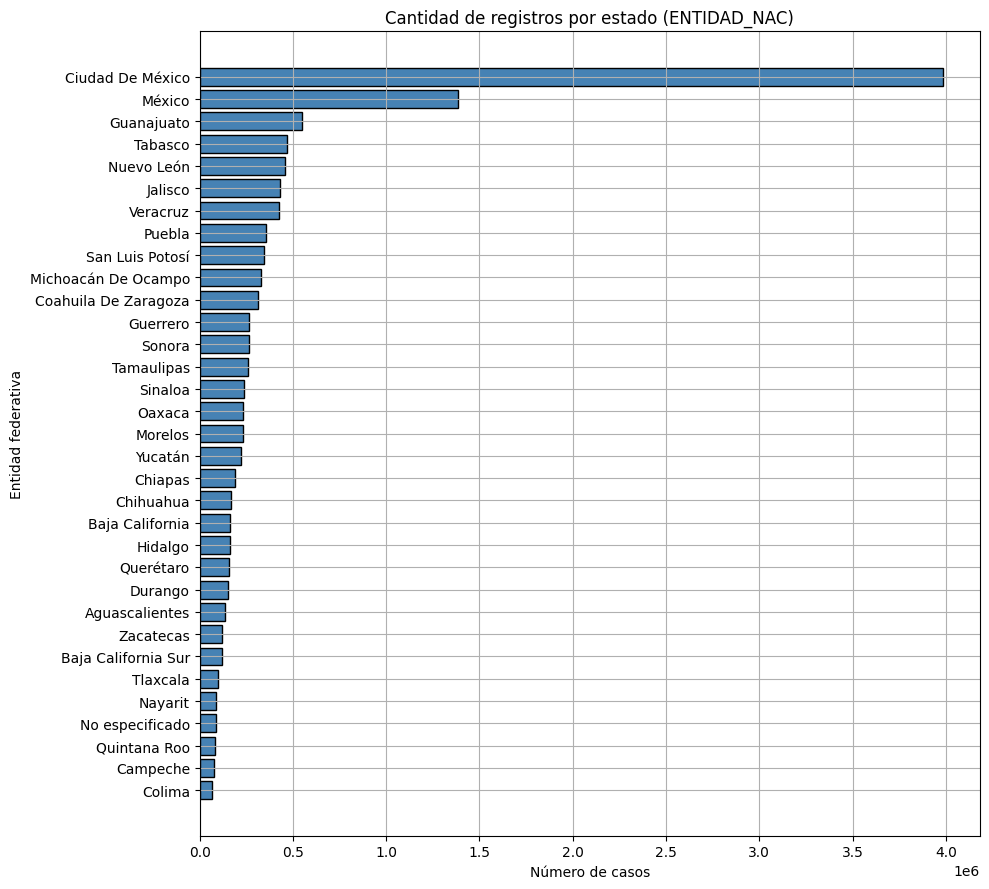

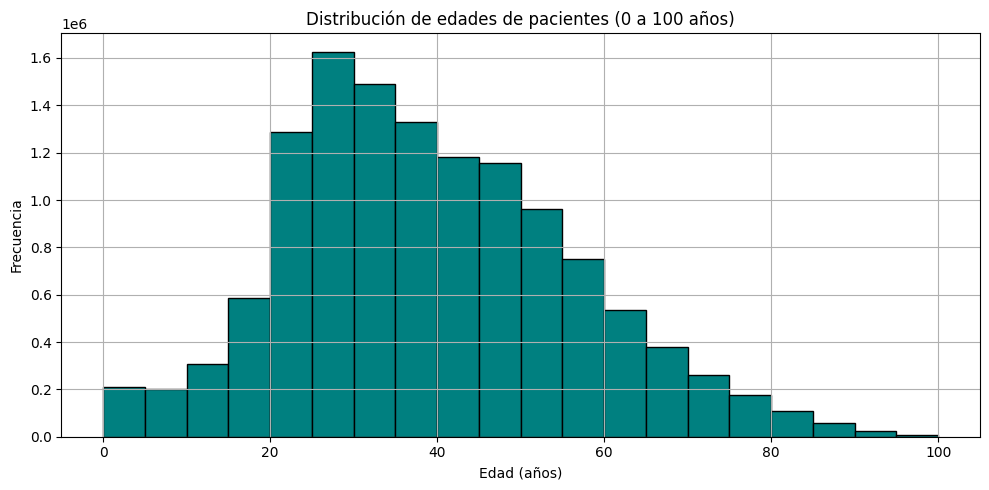

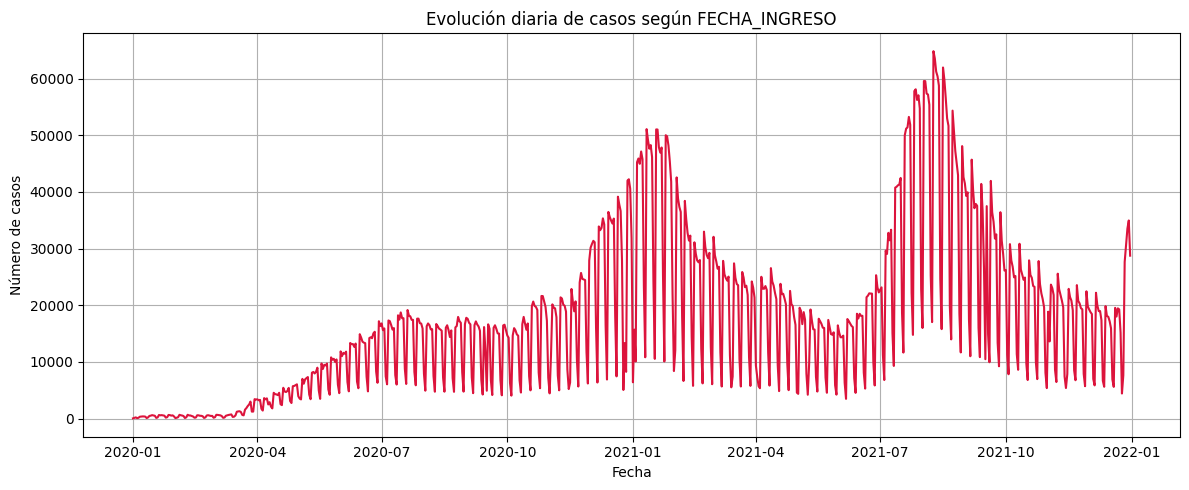

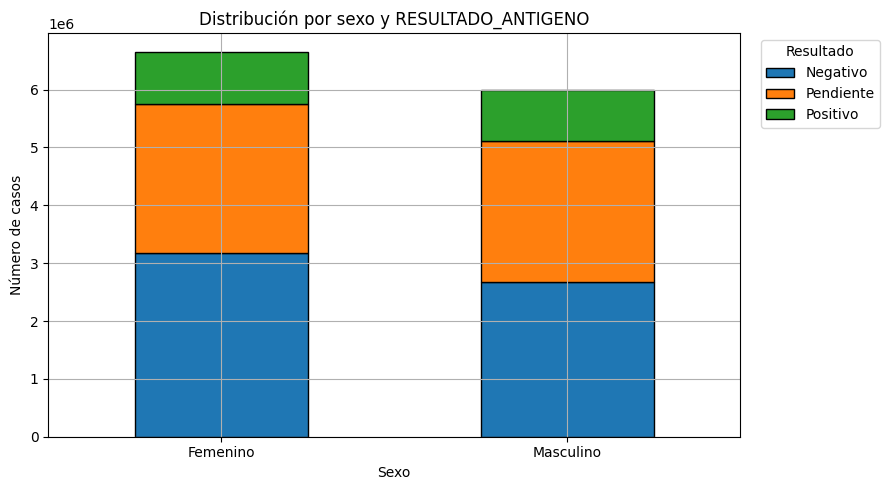

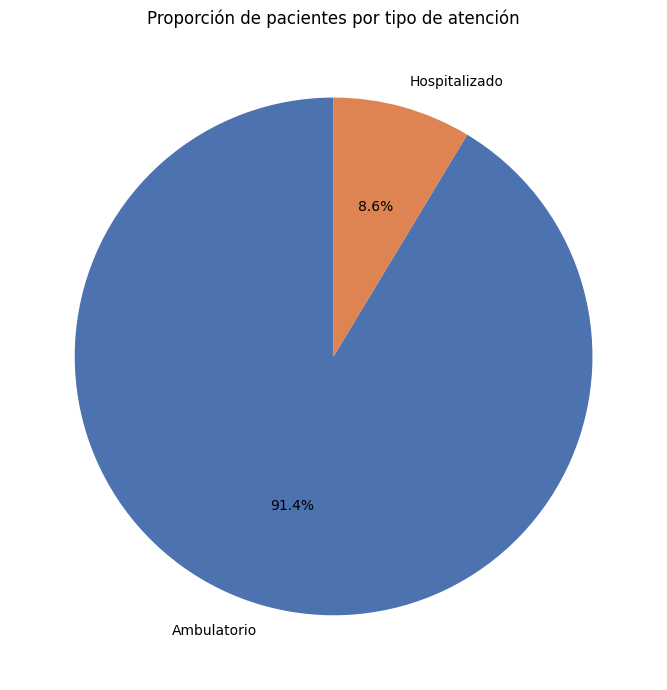

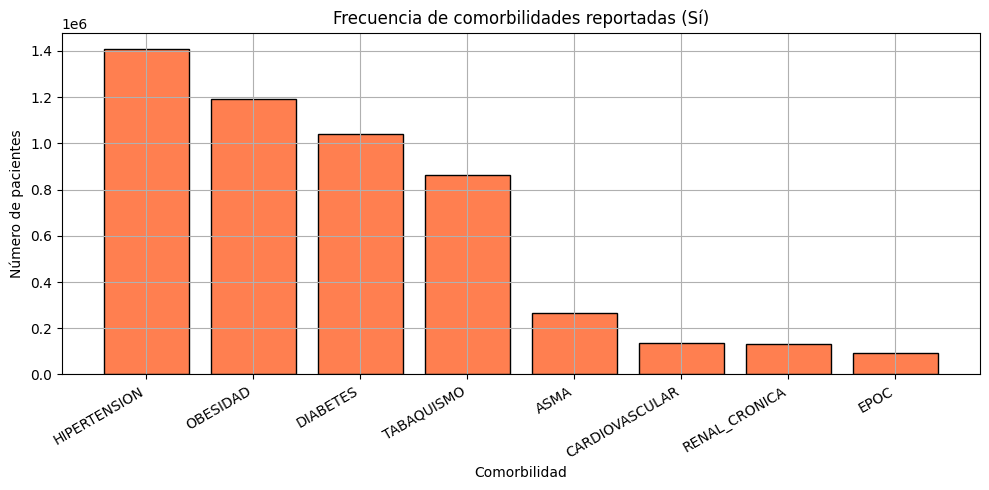

In [4]:
# 1. Gráfico de barras horizontal por estado (mayor arriba)
col_estado = (
    'ENTIDAD_RES' if 'ENTIDAD_RES' in df.columns
    else ('ENTIDAD_NAC' if 'ENTIDAD_NAC' in df.columns else None)
)

if col_estado:
    estados_serie = (
        df[col_estado]
        .replace({99: 'No especificado', '99': 'No especificado'})
        .fillna('No especificado')
    )
    conteo_estado = estados_serie.value_counts().sort_values(ascending=True)
    plt.figure(figsize=(10, 9))
    plt.barh(conteo_estado.index.astype(str), conteo_estado.values, color='steelblue', edgecolor='black')
    plt.title(f'Cantidad de registros por estado ({col_estado})')
    plt.xlabel('Número de casos')
    plt.ylabel('Entidad federativa')
    plt.tight_layout()
    plt.show()

# 2. Histograma por edad
if 'EDAD' in df.columns:
    edades_plot = df['EDAD'][(df['EDAD'] >= 0) & (df['EDAD'] <= 100)].dropna()
    plt.figure(figsize=(10, 5))
    plt.hist(edades_plot, bins=20, range=(0, 100), color='teal', edgecolor='black')
    plt.title('Distribución de edades de pacientes (0 a 100 años)')
    plt.xlabel('Edad (años)')
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

# 3. Gráfico de líneas por fecha (evolución de casos)
for cand_fecha in ['FECHA_INGRESO', 'FECHA_SINTOMAS', 'FECHA_ACTUALIZACION']:
    if cand_fecha in df.columns:
        col_fecha = cand_fecha
        break
else:
    col_fecha = None

if col_fecha:
    fechas = pd.to_datetime(df[col_fecha], errors='coerce').dropna()
    casos_diarios = fechas.value_counts().sort_index()
    plt.figure(figsize=(12, 5))
    plt.plot(casos_diarios.index, casos_diarios.values, linewidth=1.5, color='crimson')
    plt.title(f'Evolución diaria de casos según {col_fecha}')
    plt.xlabel('Fecha')
    plt.ylabel('Número de casos')
    plt.tight_layout()
    plt.show()

# 4. Gráfico de barras apiladas por sexo y resultado
if 'SEXO' in df.columns and col_resultado:
    cruce_sr = pd.crosstab(
        df['SEXO'].fillna('No especificado'),
        df[col_resultado].fillna('No especificado')
    )
    cruce_sr.plot(kind='bar', stacked=True, figsize=(9, 5), edgecolor='black')
    plt.title(f'Distribución por sexo y {col_resultado}')
    plt.xlabel('Sexo')
    plt.ylabel('Número de casos')
    plt.xticks(rotation=0)
    plt.legend(title='Resultado', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# 5. Gráfico circular por tipo de paciente
if 'TIPO_PACIENTE' in df.columns:
    tipo_pac = df['TIPO_PACIENTE'].fillna('No especificado').value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(
        tipo_pac.values,
        labels=tipo_pac.index.astype(str),
        autopct='%1.1f%%',
        startangle=90,
        colors=['#4C72B0', '#DD8452', '#55A868']
    )
    plt.title('Proporción de pacientes por tipo de atención')
    plt.tight_layout()
    plt.show()

# 6. Gráfico de barras por comorbilidad
comorbilidades = [
    'DIABETES', 'HIPERTENSION', 'OBESIDAD', 'EPOC',
    'ASMA', 'INMUSUPR', 'RENAL_CRONICA', 'CARDIOVASCULAR', 'TABAQUISMO'
]
comorb_presentes = [c for c in comorbilidades if c in df.columns]

if comorb_presentes:
    conteo_comorb = {
        c: int(df[c].fillna('').astype(str).str.strip().str.lower().isin(['si', 'sí', '1', '1.0']).sum())
        for c in comorb_presentes
    }
    serie_comorb = pd.Series(conteo_comorb).sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(serie_comorb.index, serie_comorb.values, color='coral', edgecolor='black')
    plt.title('Frecuencia de comorbilidades reportadas (Sí)')
    plt.xlabel('Comorbilidad')
    plt.ylabel('Número de pacientes')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

In [5]:
comorbilidades = [
    'DIABETES', 'HIPERTENSION', 'OBESIDAD', 'EPOC',
    'ASMA', 'INMUSUPR', 'RENAL_CRONICA', 'CARDIOVASCULAR', 'TABAQUISMO'
]
comorb_cols = [c for c in comorbilidades if c in df.columns]

# Indicador binario: 1 = 'Si', 0 = 'No', NaN = no especificado
df_comorb = pd.DataFrame(index=df.index)
for col in comorb_cols:
    vals = df[col].astype(str).str.strip().str.lower()
    es_si = vals.isin(['si', 'sí', '1', '1.0'])
    es_no = vals.isin(['no', '2', '2.0'])
    df_comorb[col] = np.where(es_si, 1.0, np.where(es_no, 0.0, np.nan))

total_general = len(df)
casos_si = df_comorb.sum(skipna=True)
validos_si_no = df_comorb.notna().sum()

# Probabilidad simple: total con comorbilidad / total general de casos
prob_simple = pd.DataFrame({
    'Total_Con_Comorbilidad': casos_si.astype(int),
    'Total_General_Casos': total_general,
    'Prob_Simple_Total': casos_si / total_general,
    'Prob_Simple_Total_%': (casos_si / total_general) * 100,
    'Prob_Simple_Validos_%': (casos_si / validos_si_no) * 100
}).sort_values(by='Prob_Simple_Total', ascending=False)

print("=== PROBABILIDAD SIMPLE POR COMORBILIDAD ===")
print(prob_simple.round(4))

# Probabilidad condicional por entidad federativa: P(Comorbilidad = Sí | Entidad)
col_ent = (
    'ENTIDAD_RES' if 'ENTIDAD_RES' in df.columns
    else ('ENTIDAD_NAC' if 'ENTIDAD_NAC' in df.columns else None)
)

if col_ent and not df_comorb.empty:
    df_temp = df_comorb.copy()
    df_temp[col_ent] = df[col_ent].replace({99: 'No especificado', '99': 'No especificado'})
    prob_condicional = df_temp.groupby(col_ent, dropna=False).mean(numeric_only=True)
    print(f"\n=== PROBABILIDAD CONDICIONAL POR {col_ent} ===")
    print(prob_condicional.round(4))

    prob_condicional.to_csv('probabilidad_condicional_comorbilidades.csv')
    print("\nArchivo 'probabilidad_condicional_comorbilidades.csv' guardado.")

=== PROBABILIDAD SIMPLE POR COMORBILIDAD ===
                Total_Con_Comorbilidad  Total_General_Casos  \
HIPERTENSION                   1407779             12634194   
OBESIDAD                       1193021             12634194   
DIABETES                       1038459             12634194   
TABAQUISMO                      865162             12634194   
ASMA                            263855             12634194   
CARDIOVASCULAR                  134410             12634194   
RENAL_CRONICA                   129874             12634194   
EPOC                             92446             12634194   

                Prob_Simple_Total  Prob_Simple_Total_%  Prob_Simple_Validos_%  
HIPERTENSION               0.1114              11.1426                11.2034  
OBESIDAD                   0.0944               9.4428                 9.4935  
DIABETES                   0.0822               8.2194                 8.2654  
TABAQUISMO                 0.0685               6.8478             

Media (mu): 2360
Desviación estándar (sigma): 714
Z para 2,000 casos: -0.5042
Z para 3,000 casos: 0.8964
Probabilidad P(2000 <= X <= 3000): 0.507910 (50.79%)


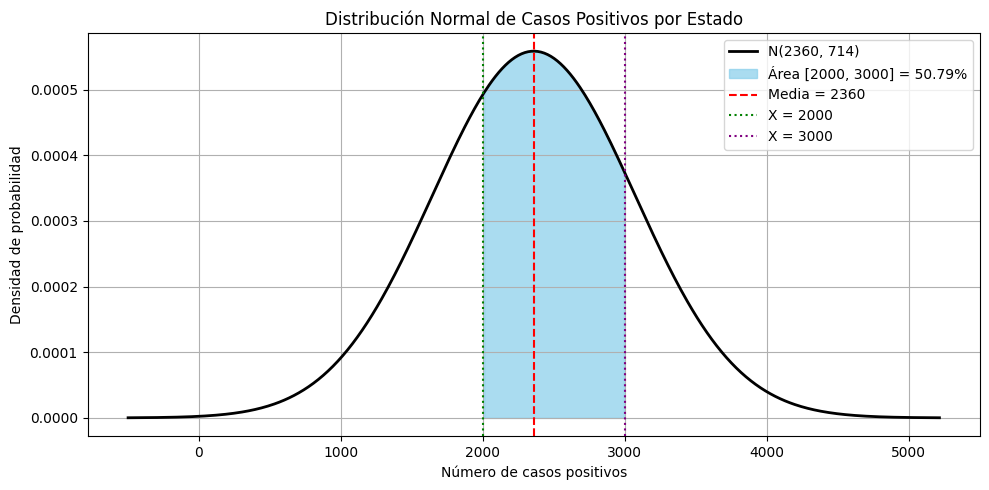

In [6]:
mu = 2360
sigma = 714

z_inf = (2000 - mu) / sigma
z_sup = (3000 - mu) / sigma

prob_entre = norm.cdf(3000, loc=mu, scale=sigma) - norm.cdf(2000, loc=mu, scale=sigma)

print(f"Media (mu): {mu}")
print(f"Desviación estándar (sigma): {sigma}")
print(f"Z para 2,000 casos: {z_inf:.4f}")
print(f"Z para 3,000 casos: {z_sup:.4f}")
print(f"Probabilidad P(2000 <= X <= 3000): {prob_entre:.6f} ({prob_entre * 100:.2f}%)")

x_vals = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
y_vals = norm.pdf(x_vals, loc=mu, scale=sigma)

plt.figure(figsize=(10, 5))
plt.plot(x_vals, y_vals, color='black', linewidth=2, label='N(2360, 714)')
mask = (x_vals >= 2000) & (x_vals <= 3000)
plt.fill_between(x_vals[mask], y_vals[mask], color='skyblue', alpha=0.7, label=f'Área [2000, 3000] = {prob_entre*100:.2f}%')
plt.axvline(mu, color='red', linestyle='--', label=f'Media = {mu}')
plt.axvline(2000, color='green', linestyle=':', label='X = 2000')
plt.axvline(3000, color='purple', linestyle=':', label='X = 3000')
plt.title('Distribución Normal de Casos Positivos por Estado')
plt.xlabel('Número de casos positivos')
plt.ylabel('Densidad de probabilidad')
plt.legend()
plt.tight_layout()
plt.show()

## **Interpretación general de resultados**

A partir del análisis de los 12,634,194 registros de COVID-19, se observa que predominan ampliamente los pacientes ambulatorios frente a los hospitalizados, concentrándose en población adulta joven y media con picos definidos en las olas de contagio. Entre las comorbilidades, la hipertensión, la obesidad y la diabetes presentan las mayores probabilidades simples, variando de forma condicional según cada entidad federativa; además, bajo una distribución normal ($\mu = 2360$, $\sigma = 714$), la probabilidad de que un estado registre entre 2,000 y 3,000 casos positivos es de **50.79%**.

## **Conclusión**

En este proyecto apliqué conceptos clave de probabilidad y estadística descriptiva sobre un volumen real de datos masivos. Usar Python con pandas y matplotlib en Google Colab facilitó la limpieza de registros, el cálculo de probabilidades condicionadas y la visualización clara de tendencias epidemiológicas.